# INDUSTRIAL MACHINE FAILURE PREDCTION

Submitted by : Spoorti K Patil (251090700083), Poojitha Acharya (251090700066)
Subject : Machine Learning Lab (Mini Project)
Phase 1.

## Problem Statement

Industrial machines can experience unexpected failures due to different
operating conditions such as temperature, rotational speed, torque and
tool wear. These failures can cause production downtime and maintenance
costs. Therefore, this project aims to develop a machine learning model
that can predict whether an industrial machine will fail based on its
operating conditions.
## Objective of project:
To analyze industrial machine sensor data and identify patterns associated
with machine failures. The cleaned dataset will be prepared for machine
learning to predict whether a machine is likely to fail.

Dataset : ai4i2020.csv

Target variables :
Machine failure - 0 = No failure , 1 = Failure

In [3]:
# IMPORT LIBRARIES
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score, precision_score, f1_score, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

Meta-Data :
1. UDI (Integer) - Unique identification number
2. Product ID (Object) - Unique identification code of the product
3. Type (object) - Product type caategory. (L,M and H type)
4. Air temperature[K] (Float) - Temperature of the surrounding air measured in kelvin
5. Process temperature (Float) - Temperature of the industrial process
6. Rotational speed[rpm] (Integer) - Rotational speed of the machine measured in revolutions per minute
7. Torque[Nm] (Float) - measured in Newton-meters
8. Tool wear[min] (Integer) - measured in minutes of tool usage
9. Machine Failure - 0 = No Failure , 1 = Failure
10. TWF (Integer) - Tool Wear Failure indicator 0 = No, 1 = Yes
11.	HDF	(Integer)	- Heat Dissipation Failure indicator 0 = No, 1 = Yes.
12.	PWF	(Integer)	- Power Failure indicator 0 = No, 1 = Yes.
13.	OSF	(Integer)	- Overstrain Failure indicator 0 = No, 1 = Yes.
14.	RNF	(Integer)	- Random Failure indicator 0 = No, 1 = Yes.
-Categorical Features: Product ID, Type
- Numerical Features: UDI, temperature, rotational speed, torque,
  tool wear and failure indicators

In [4]:
# LOAD DATASET
df = pd.read_csv("ai4i2020.csv")

In [5]:
# METADATA OF DATA
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [6]:
df.shape

(10000, 14)

Rows : 10000
Columns : 14

In [7]:
# Display all column names in the dataset
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='object')

In [8]:
# Display dataset structure, data types, non-null values,
# and memory usage
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [9]:
# Generate descriptive statistics for numerical variables
# This includes count, mean, standard deviation,
# minimum, quartiles, and maximum values
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [10]:
# Count the number of missing values in each column
df.isnull().sum()

,0
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0


In [11]:
# Count the number of completely duplicated rows
df.duplicated().sum()

np.int64(0)

In [12]:
# Display the data type of every column
df.dtypes

,0
UDI,int64
Product ID,object
Type,object
Air temperature [K],float64
Process temperature [K],float64
Rotational speed [rpm],int64
Torque [Nm],float64
Tool wear [min],int64
Machine failure,int64
TWF,int64


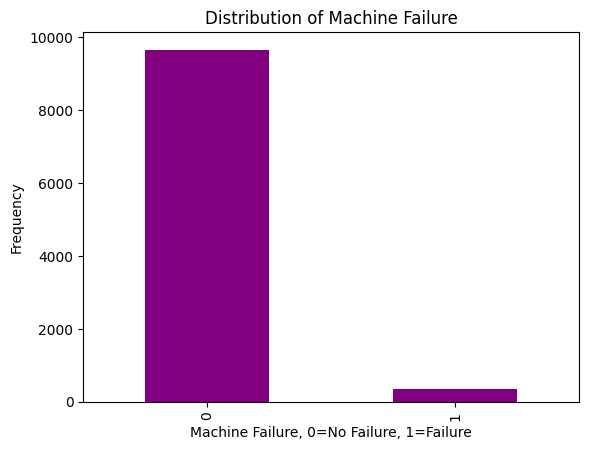

In [13]:
# EXPLORATORY DATA ANALYSIS

# Count the number of machines with and without failure
df["Machine failure"].value_counts()

# Visualize the distribution of machine failure
df["Machine failure"].value_counts().plot(kind="bar", color="purple")
plt.xlabel("Machine Failure, 0=No Failure, 1=Failure")
plt.ylabel("Frequency")
plt.title("Distribution of Machine Failure")
plt.show()

# Dataset is highly imbalanced because non-failure cases
# are much more common than failure cases.

Result : 0(No failure) = 9661 , 1(Failure) = 339

In [14]:
# Count the number of observations belonging to each product type
df["Type"].value_counts()

,count
Type,
L,6000
M,2997
H,1003


Type L represents the majority of observations, while Type H represents the smallest group.

In [15]:
# Select the main numerical machine operating features
numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

# Descriptive statistics for the selected senor variables
df[numerical_features].describe()



,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,300.004930,310.005560,1538.776100,39.986910,107.951000
std,2.000259,1.483734,179.284096,9.968934,63.654147
min,295.300000,305.700000,1168.000000,3.800000,0.000000
25%,298.300000,308.800000,1423.000000,33.200000,53.000000
50%,300.100000,310.100000,1503.000000,40.100000,108.000000
75%,301.500000,311.100000,1612.000000,46.800000,162.000000
max,304.500000,313.800000,2886.000000,76.600000,253.000000


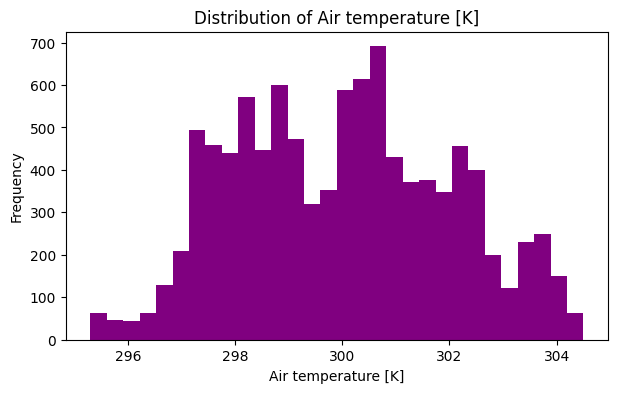

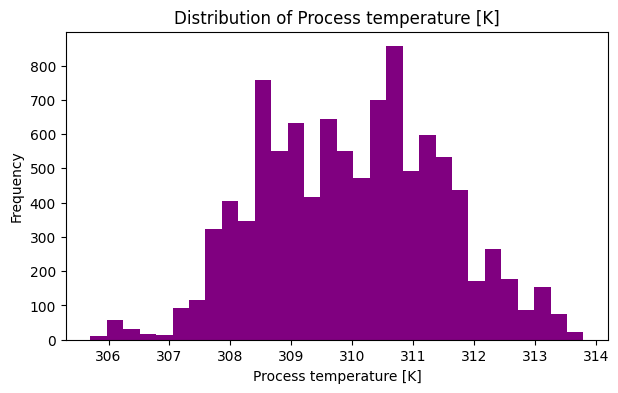

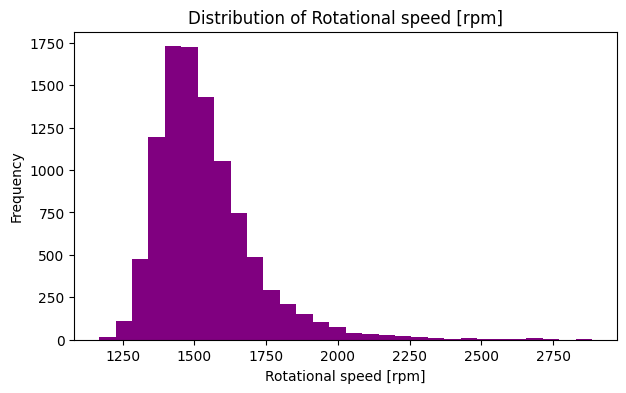

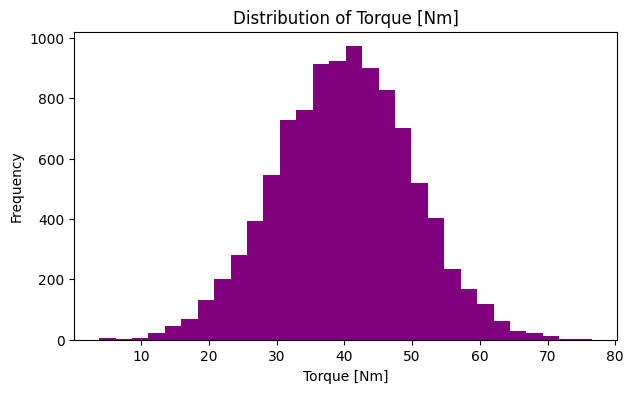

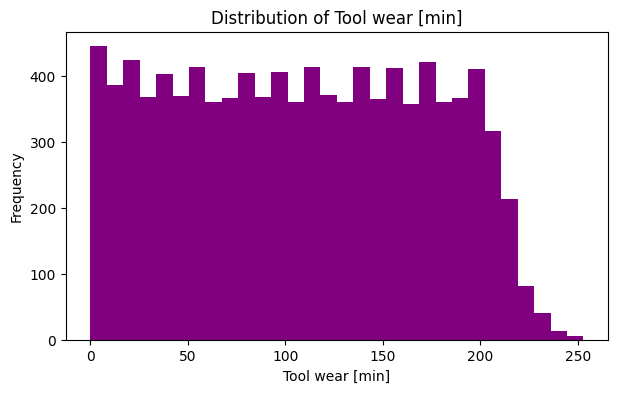

In [16]:
# Plot histograms for each numerical feature
# Histograms help us understand the distribution of the sensor values
for col in numerical_features:
    plt.figure(figsize=(7, 4))

    plt.hist(df[col], bins=30, color="purple")

    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.title(f"Distribution of {col}")

    plt.show()

The process temperature is mostly concentrated around 308–311 K, rotational speed around 1,400–1,700 rpm and torque around 30–50 Nm. Tool wear is broadly distributed up to about 250 minutes, while air temperature is mainly concentrated around 297–303 K.

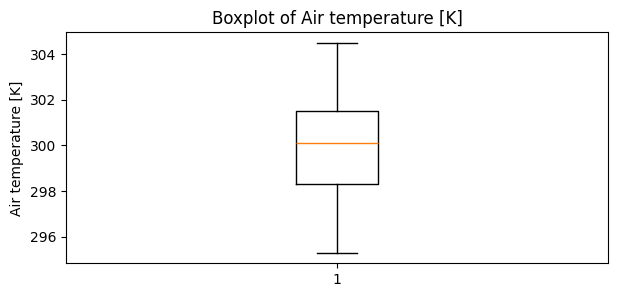

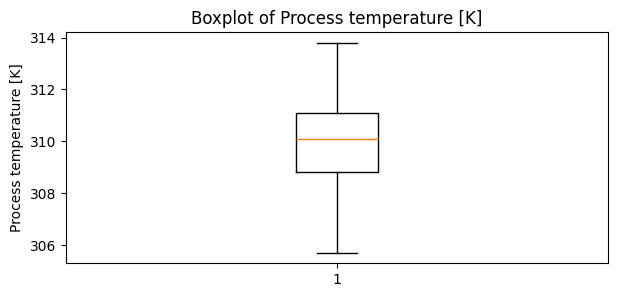

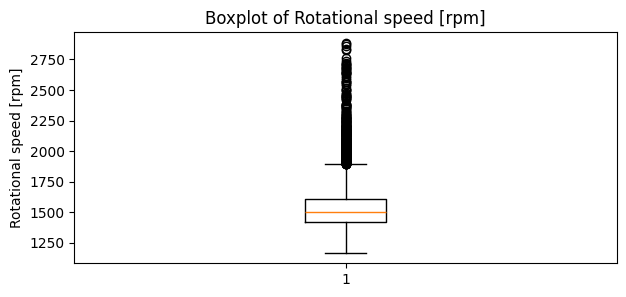

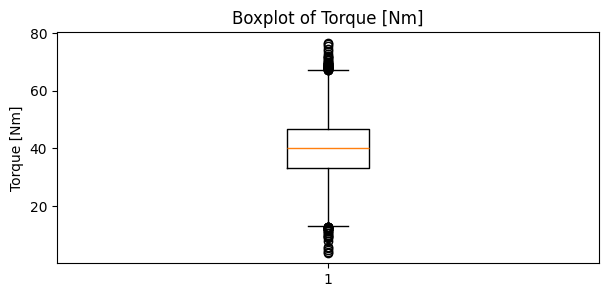

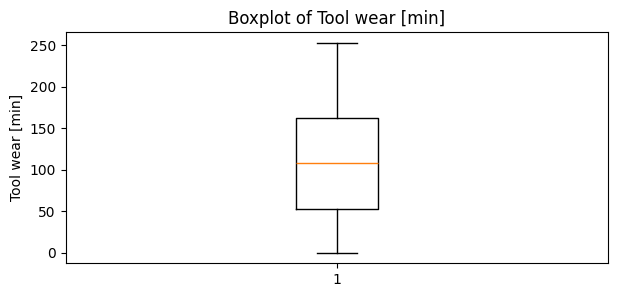

In [17]:
# Identify possible outliers using boxplots
for col in numerical_features:
    plt.figure(figsize=(7, 3))
    plt.boxplot(df[col])
    plt.ylabel(col)
    plt.title(f"Boxplot of {col}")
    plt.show()

* Air temperature: Values are fairly stable around 300 K, with low variation and no major outliers.
* Process temperature: Centered around 310 K with moderate variation and no clear outliers.
* Rotational speed: Centered around 1500 rpm, with many high-value outliers, indicating strong right-skewness.
* Torque: Centered around 40 Nm, with several outliers on both low and high sides.
* Tool wear: Shows large variation (0–250 min), but no significant outliers.

* Overall: Temperature variables are relatively stable, while rotational speed and torque contain noticeable outliers; tool wear has the widest spread.

In [18]:
for col in ["Torque [Nm]", "Rotational speed [rpm]"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(col)
    print("Lower limit:", lower)
    print("Upper limit:", upper)
    print("Number of outliers:", len(outliers))
    print("Total outliers:", len(outliers),"\n")
    print("Machine failures among outliers:")
    print(outliers["Machine failure"].value_counts())

Torque [Nm]
Lower limit: 12.800000000000011
Upper limit: 67.19999999999999
Number of outliers: 69
Total outliers: 69 

Machine failures among outliers:
Machine failure
1    62
0     7
Name: count, dtype: int64
Rotational speed [rpm]
Lower limit: 1139.5
Upper limit: 1895.5
Number of outliers: 418
Total outliers: 418 

Machine failures among outliers:
Machine failure
0    383
1     35
Name: count, dtype: int64


*   These are industrial sensor measurements, and extreme values may be genuine.
*   Most Torque outliers in your dataset are associated with failures.
*   Removing these observations could cause the model to lose important information
*  Removing these observations could cause the model to lose important information.
*   The IQR method identifies statistical outliers, but it cannot establish that measurements are incorrect.



In [19]:
# Compare the average value of each sensor feature between failed and non-failed machines.

for col in numerical_features:
    print("\n", col)

    # calculating the mean feature value for each machine failure class
    print(df.groupby("Machine failure")[col].mean())


 Air temperature [K]
Machine failure
0    299.973999
1    300.886431
Name: Air temperature [K], dtype: float64

 Process temperature [K]
Machine failure
0    309.995570
1    310.290265
Name: Process temperature [K], dtype: float64

 Rotational speed [rpm]
Machine failure
0    1540.260014
1    1496.486726
Name: Rotational speed [rpm], dtype: float64

 Torque [Nm]
Machine failure
0    39.629655
1    50.168142
Name: Torque [Nm], dtype: float64

 Tool wear [min]
Machine failure
0    106.693717
1    143.781711
Name: Tool wear [min], dtype: float64


The failed machines show:

-higher average air temperature
-slightly higher process temperature
-lower average rotational speed
-higher torque
-higher tool wear

In [20]:
# Calculate the correlation matrix for numerical variables
corr_matrix=df.corr(numeric_only=True)

# Display correlations of all numerical variables with Machine failure
# Higher absolute correlation indicates a stronger linear relationship
print(corr_matrix["Machine failure"].sort_values(ascending=False))

Machine failure            1.000000
HDF                        0.575800
OSF                        0.531083
PWF                        0.522812
TWF                        0.362904
Torque [Nm]                0.191321
Tool wear [min]            0.105448
Air temperature [K]        0.082556
Process temperature [K]    0.035946
RNF                        0.004516
UDI                       -0.022892
Rotational speed [rpm]    -0.044188
Name: Machine failure, dtype: float64


In [21]:
# The columns representing specific machine failure types
failure_columns = ["TWF", "HDF", "PWF", "OSF", "RNF"]

# The frequency of 0 and 1 for each failure type
for col in failure_columns:
    print(col, df[col].value_counts().to_dict())

TWF {0: 9954, 1: 46}
HDF {0: 9885, 1: 115}
PWF {0: 9905, 1: 95}
OSF {0: 9902, 1: 98}
RNF {0: 9981, 1: 19}


Among the failure types:

HDF occurs most frequently: 115
OSF: 98
PWF: 95
TWF: 46
RNF: 19

All failure types are relatively rare compared with normal observations.

In [22]:
# Calculating the proportion of machine failures when each specific failure indicator is equal to 1.
for col in failure_columns:
    print(col, "Failure rate when 1 =", df[df[col] == 1]["Machine failure"].mean())

TWF Failure rate when 1 = 1.0
HDF Failure rate when 1 = 1.0
PWF Failure rate when 1 = 1.0
OSF Failure rate when 1 = 1.0
RNF Failure rate when 1 = 0.05263157894736842


The overall Machine failure is also 1 in this dataset.
Therefore, these variables are extremely strongly related to the target and can cause target leakage if directly used for prediction.

RNF behaves differently, with only about 5.26% of RNF=1 records corresponding to machine failure.

This provides a strong reason for removing these failure-indicator columns before modeling.

In [23]:
# DATA CLEANING

# Remove identifier columns that do not provide useful predictive information
# and failure-type columns that are directly related to the target variable.
remove_columns=["UDI","Product ID","TWF","HDF","PWF","OSF","RNF"]

# cleaned dataset after removing the columns
df_clean=df.drop(columns=remove_columns)

TWF, HDF, PWF, OSF, RNF are faailure indicators and are highly associated with the target, keeping them could result in data leakage, where the model gets information about failure that would not be appropriate as an independent predictive input.

In [24]:
# Check the table after removing the columns
df_clean.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0


In [25]:
# Check the dimensions of the cleaned dataset
df_clean.shape

(10000, 7)

Original : 10000 rows * 14 columns
New : 10000 rows * 7 columns

In [26]:
# Display the columns remaining after data cleaning
df_clean.columns

Index(['Type', 'Air temperature [K]', 'Process temperature [K]',
       'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]',
       'Machine failure'],
      dtype='object')

In [27]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Type                     10000 non-null  object 
 1   Air temperature [K]      10000 non-null  float64
 2   Process temperature [K]  10000 non-null  float64
 3   Rotational speed [rpm]   10000 non-null  int64  
 4   Torque [Nm]              10000 non-null  float64
 5   Tool wear [min]          10000 non-null  int64  
 6   Machine failure          10000 non-null  int64  
dtypes: float64(3), int64(3), object(1)
memory usage: 547.0+ KB


In [28]:
df_clean.describe()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900
std,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981
min,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000
25%,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000
50%,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000
75%,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000
max,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000


In [29]:
# Check for missing values after data cleaning
df_clean.isnull().sum()

,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0


There are still 0 missing values, so missing value treatment is not required.

In [30]:
# Duplicate rows checking in the cleaned dataset
df_clean.duplicated().sum()

np.int64(0)

In [31]:
print("The dataset does not contain duplicate rows , no duplicate removal is necessary.")

The dataset does not contain duplicate rows , no duplicate removal is necessary.


In [32]:
# PREPROCESSING

# Separate independent features (X) and target variable (y)
# X contains the machine operating parameters
# y contains the Machine failure outcome:
# 0 = No Failure, 1 = Failure

x=df_clean.drop(columns=["Machine failure"])
y=df_clean["Machine failure"]

In [33]:
# Split the dataset into training and testing sets
# 80% of the data is used for training and 20% for testing.
# random_state=42 ensures that the same split is obtained every time.
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 42, stratify = y)

In [34]:
# Pipeline prcessing (Onehot encoding and Standard scaler)
# StandardScaler is used to standardize numerical features.
# SMOTE is used to handle class imbalance in the target variable.

numeric_cols = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]
categoric_cols = ["Type"]

In [35]:
# Categorical data is converted into numerical form using One-Hot Encoding.
# Numerical features are standardized using StandardScaler.
preprocessor = ColumnTransformer(
    transformers = [
                  ("categorical",OneHotEncoder(handle_unknown="ignore"), categoric_cols),
                  ("numerical",StandardScaler(),numeric_cols)
                  ]
)


In [36]:
# First: preprocessing is performed.
# Second: SMOTE generates synthetic samples for the minority class.

In [37]:
# 1. Decision Tree Classifier
dt_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("smote", SMOTE(random_state = 42)),
    ("model", DecisionTreeClassifier(random_state=42))
])

dt_pipeline.fit(x_train,y_train)
y_pred_dt = dt_pipeline.predict(x_test)
y_prob_dt = dt_pipeline.predict_proba(x_test)[:,1]

In [38]:
dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_recall = recall_score(y_test, y_pred_dt)
dt_precision = precision_score(y_test, y_pred_dt)
dt_f1 = f1_score(y_test, y_pred_dt)
dt_roc_auc = roc_auc_score(y_test, y_prob_dt)
dt_cm = confusion_matrix(y_test, y_pred_dt)

print("Confusion Matrix of Decision Tree:\n",dt_cm)
print("Accuracy of Decision Tree:",dt_accuracy*100,"%")
print("Recall of Decision Tree:",dt_recall*100,"%")
print("Precision of Decision Tree:",dt_precision*100,"%")
print("F1 Score of Decision Tree:",dt_f1*100,"%")
print("ROCAUC of Decision Tree:",dt_roc_auc*100,"%")

Confusion Matrix of Decision Tree:
 [[1872   60]
 [  18   50]]
Accuracy of Decision Tree: 96.1 %
Recall of Decision Tree: 73.52941176470588 %
Precision of Decision Tree: 45.45454545454545 %
F1 Score of Decision Tree: 56.17977528089888 %
ROCAUC of Decision Tree: 85.21191085129705 %


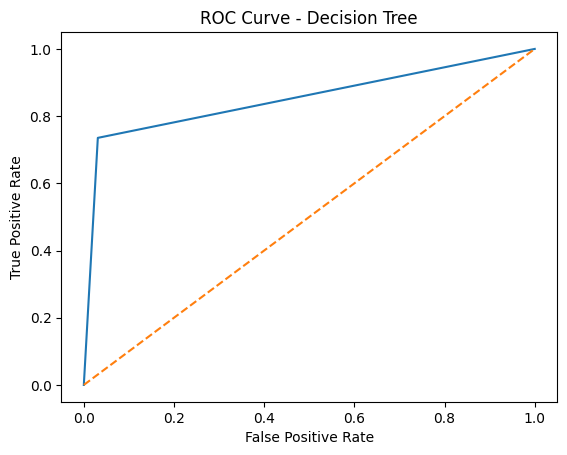

The ROC curve lies above the random baseline, and the ROC-AUC of 0.850 indicates that 
the Decision Tree has good class-discrimination ability across different thresholds.


In [39]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob_dt)

plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Decision Tree")
plt.show()

print("The ROC curve lies above the random baseline, and the ROC-AUC of 0.850 indicates that ")
print("the Decision Tree has good class-discrimination ability across different thresholds.")

In [40]:
# 2. Support Vector Machine (SVM)
svm_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("smote", SMOTE(random_state = 42)),
    ("model",SVC(kernel = "rbf", probability = True) )
])

svm_pipeline.fit(x_train,y_train)
y_pred_svm = svm_pipeline.predict(x_test)
y_prob_svm = svm_pipeline.predict_proba(x_test)[:,1]

In [41]:
svm_accuracy = accuracy_score(y_test, y_pred_svm)
svm_recall = recall_score(y_test, y_pred_svm)
svm_precision = precision_score(y_test, y_pred_svm)
svm_f1 = f1_score(y_test, y_pred_svm)
svm_roc_auc = roc_auc_score(y_test, y_prob_svm)
svm_cm = confusion_matrix(y_test, y_pred_svm)

print("Confusion Matrix of Support Vector Machine:\n",svm_cm)
print("Accuracy of Support Vector Machine:",svm_accuracy*100,"%")
print("Recall of Support Vector Machine:",svm_recall*100,"%")
print("Precision of Support Vector Machine:",svm_precision*100,"%")
print("F1 Score of Support Vector Machine:",svm_f1*100,"%")
print("ROCAUC of Support Vector Machine:",svm_roc_auc*100,"%")

Confusion Matrix of Support Vector Machine:
 [[1785  147]
 [   7   61]]
Accuracy of Support Vector Machine: 92.30000000000001 %
Recall of Support Vector Machine: 89.70588235294117 %
Precision of Support Vector Machine: 29.326923076923077 %
F1 Score of Support Vector Machine: 44.20289855072464 %
ROCAUC of Support Vector Machine: 96.55873218852759 %


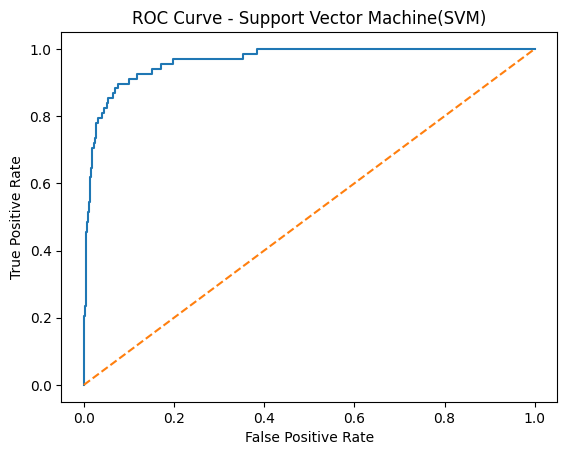

The ROC curve lies above the random baseline, and the ROC-AUC of 0.96 indicates that Support Vector Machine (SVM) has good class-discrimination ability across different thresholds.


In [42]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob_svm)

plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Support Vector Machine(SVM)")
plt.show()

print("The ROC curve lies above the random baseline, and the ROC-AUC of 0.96 indicates that Support Vector Machine (SVM) has good class-discrimination ability across different thresholds.")

In [43]:
# 3. XGBoost Classifier
xg_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("smote", SMOTE(random_state = 42)),
    ("model", XGBClassifier(n_estimators=100, random_state=42, eval_metric = "logloss"))
])

xg_pipeline.fit(x_train,y_train)
y_pred_xg = xg_pipeline.predict(x_test)
y_prob_xg = xg_pipeline.predict_proba(x_test)[:,1]

In [44]:
xg_accuracy = accuracy_score(y_test, y_pred_xg)
xg_recall = recall_score(y_test, y_pred_xg)
xg_precision = precision_score(y_test, y_pred_xg)
xg_f1 = f1_score(y_test, y_pred_xg)
xg_roc_auc = roc_auc_score(y_test, y_prob_xg)
xg_cm = confusion_matrix(y_test, y_pred_xg)

print("Confusion Matrix of XGBoost:\n",xg_cm)
print("Accuracy of XGBoost:",xg_accuracy*100,"%")
print("Recall of XGBoost:",xg_recall*100,"%")
print("Precision of XGBoost:",xg_precision*100,"%")
print("F1 Score of XGBoost:",xg_f1*100,"%")
print("ROCAUC of XGBoost:",xg_roc_auc*100,"%")

Confusion Matrix of XGBoost:
 [[1905   27]
 [  13   55]]
Accuracy of XGBoost: 98.0 %
Recall of XGBoost: 80.88235294117648 %
Precision of XGBoost: 67.07317073170732 %
F1 Score of XGBoost: 73.33333333333333 %
ROCAUC of XGBoost: 97.00706369504323 %


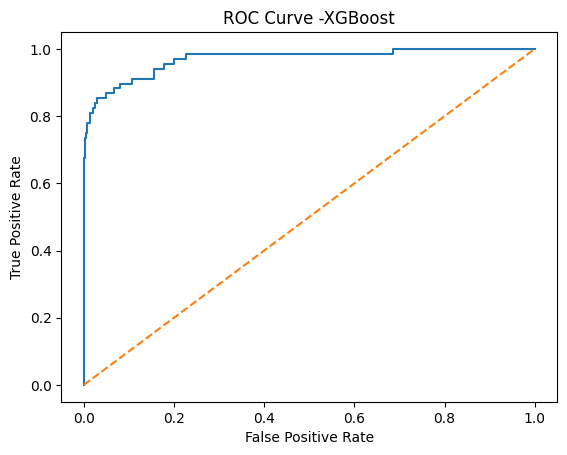

The ROC curve lies above the random baseline, and the ROC-AUC of 0.9719 indicates that 
XGBoost has excellent class-discrimination ability across different thresholds.


In [45]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob_xg)

plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve -XGBoost")
plt.show()

print("The ROC curve lies above the random baseline, and the ROC-AUC of 0.9719 indicates that ")
print("XGBoost has excellent class-discrimination ability across different thresholds.")

In [46]:
# Comparision
comparison = pd.DataFrame({
    "Model": ["Decision Tree", "SVM", "XGBoost"],

    "Accuracy": [dt_accuracy, svm_accuracy, xg_accuracy],

    "Precision": [dt_precision, svm_precision, xg_precision],

    "Recall": [dt_recall, svm_recall, xg_recall],

    "F1 Score": [dt_f1, svm_f1, xg_f1],

    "ROC-AUC": [dt_roc_auc, svm_roc_auc, xg_roc_auc]
})

comparison.iloc[:, 1:] = comparison.iloc[:, 1:] * 100
comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Decision Tree,96.1,45.454545,73.529412,56.179775,85.211911
1,SVM,92.3,29.326923,89.705882,44.202899,96.558732
2,XGBoost,98.0,67.073171,80.882353,73.333333,97.007064


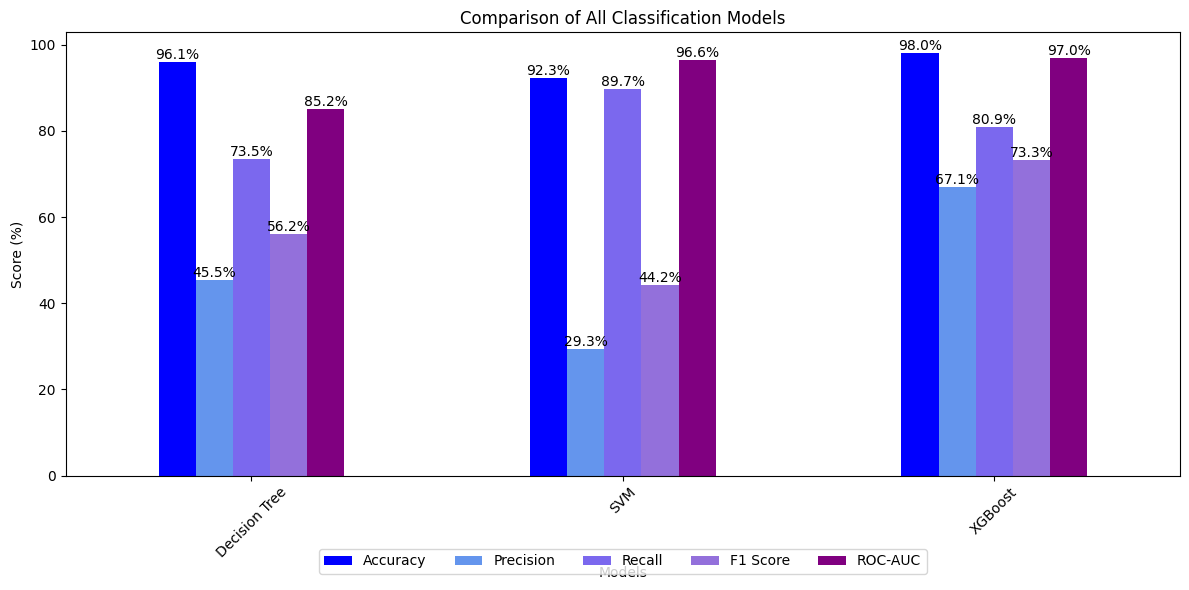

In [47]:
import matplotlib.pyplot as plt

ax = comparison.set_index("Model").plot(kind="bar",figsize=(12, 6),color=["blue", "cornflowerblue", "mediumslateblue", "mediumpurple", "purple"])

plt.title("Comparison of All Classification Models")
plt.xlabel("Models")
plt.ylabel("Score (%)")
plt.xticks(rotation=45)

# Show percentage on each bar
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f%%")

# Move legend to bottom
plt.legend(loc="upper center",bbox_to_anchor=(0.5, -0.15),ncol=5)

plt.tight_layout()
plt.show()

In [48]:
print("Accuracy shows the percentage of all predictions that were correct; XGBoost achieved 98%.")
print("Precision shows how many machines predicted as failures were actually failures; XGBoost achieved the highest 67.1%.")
print("Recall shows how many actual failures were detected; XGBoost detected 80.88%, while SVM had the highest recall of 89.71%.")
print("F1-score balances precision and recall; XGBoost achieved the highest 73.3%.")
print("ROC-AUC shows how well the model separates failure and non-failure cases; XGBoost achieved the highest 97%.")

Accuracy shows the percentage of all predictions that were correct; XGBoost achieved 98%.
Precision shows how many machines predicted as failures were actually failures; XGBoost achieved the highest 67.1%.
Recall shows how many actual failures were detected; XGBoost detected 80.88%, while SVM had the highest recall of 89.71%.
F1-score balances precision and recall; XGBoost achieved the highest 73.3%.
ROC-AUC shows how well the model separates failure and non-failure cases; XGBoost achieved the highest 97%.


## XGBoost is the best overall model because it has the highest accuracy, precision, F1-score, and ROC-AUC. However, SVM has higher recall, so it detects a larger proportion of actual failures. If detecting as many failures as possible is your primary objective, SVM deserves consideration; otherwise, XGBoost offers the stronger overall balance.

In [54]:
xgb_model = xg_pipeline.named_steps["model"]

xgb_model.save_model("xgboost_model.json")

print("XGBoost model saved successfully!")

XGBoost model saved successfully!


In [55]:
import joblib

preprocessing = xg_pipeline.named_steps["preprocessing"]

joblib.dump(preprocessing, "preprocessing.pkl")

print("Preprocessing saved successfully!")

Preprocessing saved successfully!
